# Notebook 1 — Exploratory Data Analysis
## Forensic Network Analysis: The Epstein Corpus

**Obiettivi di questo notebook:**
1. Valutazione della qualità e completezza del dataset (missing data, error rate)
2. Esplorazione della struttura documentale e relazionale del corpus
3. Analisi orientata alle Research Questions (RQ1 · RQ2 · RQ3)
4. Generazione del dataset master `edges_base.csv` per la pipeline NLP

**Output:** `../data/edges_base.csv`


In [31]:
# ==============================================================================
# CELLA 1 — IMPORTS & CONFIGURAZIONE GLOBALE
# ==============================================================================

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import json, os, re, warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.autolayout': True,
                     'axes.spines.top': False, 'axes.spines.right': False})

DB_PATH = '../data/document_analysis.db'
if not os.path.exists(DB_PATH):
    raise FileNotFoundError(f'Database non trovato: {DB_PATH}')

conn = sqlite3.connect(DB_PATH)
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist()
print(f'Connessione al database: OK')
print(f'Tabelle disponibili: {tables}')


Connessione al database: OK
Tabelle disponibili: ['documents', 'sqlite_sequence', 'rdf_triples', 'entity_aliases', 'tag_embeddings', 'canonical_entities']


In [32]:
# ==============================================================================
# CELLA 2 — QUALITA' DEI DATI: MISSING VALUES & VOLUMI
# ==============================================================================
# Prima di qualsiasi analisi, quantifichiamo cosa manca.
# Il 42% di timestamp mancanti e' un dato critico per la RQ1:
# significa che quasi la meta' delle relazioni non puo' essere collocata nel tempo.

q = '''
SELECT
    COUNT(*) AS total_triples,
    SUM(CASE WHEN timestamp IS NULL OR timestamp = '' THEN 1 ELSE 0 END) AS miss_timestamp,
    SUM(CASE WHEN location  IS NULL OR location  = '' THEN 1 ELSE 0 END) AS miss_location,
    SUM(CASE WHEN actor     IS NULL OR actor     = '' THEN 1 ELSE 0 END) AS miss_actor,
    SUM(CASE WHEN target    IS NULL OR target    = '' THEN 1 ELSE 0 END) AS miss_target,
    SUM(CASE WHEN action    IS NULL OR action    = '' THEN 1 ELSE 0 END) AS miss_action
FROM rdf_triples
'''
df_q = pd.read_sql_query(q, conn)
total = df_q['total_triples'].iloc[0]

print('=' * 58)
print('  QUALITA\' DEI DATI — rdf_triples')
print('=' * 58)
print(f'  Relazioni totali:          {total:>10,}')
print('-' * 58)
for f in ['timestamp','location','actor','target','action']:
    n   = df_q[f'miss_{f}'].iloc[0]
    pct = n / total * 100
    bar = ('|' * int(pct/5)).ljust(20)
    print(f'  {f:<12} mancanti: {n:>8,}  ({pct:5.1f}%)  [{bar}]')
print('=' * 58)

df_docs = pd.read_sql_query('''
    SELECT COUNT(*) AS total_docs,
           SUM(CASE WHEN error IS NOT NULL AND error != '' THEN 1 END) AS errors
    FROM documents
''', conn)
td = df_docs['total_docs'].iloc[0]
fe = df_docs['errors'].iloc[0]
print(f'  CORPUS: documents')
print('=' * 58)
print(f'  Documenti totali:          {td:>10,}')
print(f'  Documenti con errori AI:   {fe:>10,}  ({fe/td*100:.1f}%)')
print(f'  Tasso di successo:         {(td-fe)/td*100:>9.1f}%')
print('=' * 58)


  QUALITA' DEI DATI — rdf_triples
  Relazioni totali:             107,030
----------------------------------------------------------
  timestamp    mancanti:   45,549  ( 42.6%)  [||||||||            ]
  location     mancanti:   73,365  ( 68.5%)  [|||||||||||||       ]
  actor        mancanti:        0  (  0.0%)  [                    ]
  target       mancanti:        0  (  0.0%)  [                    ]
  action       mancanti:        0  (  0.0%)  [                    ]
  CORPUS: documents
  Documenti totali:              25,232
  Documenti con errori AI:        4,084  (16.2%)
  Tasso di successo:              83.8%


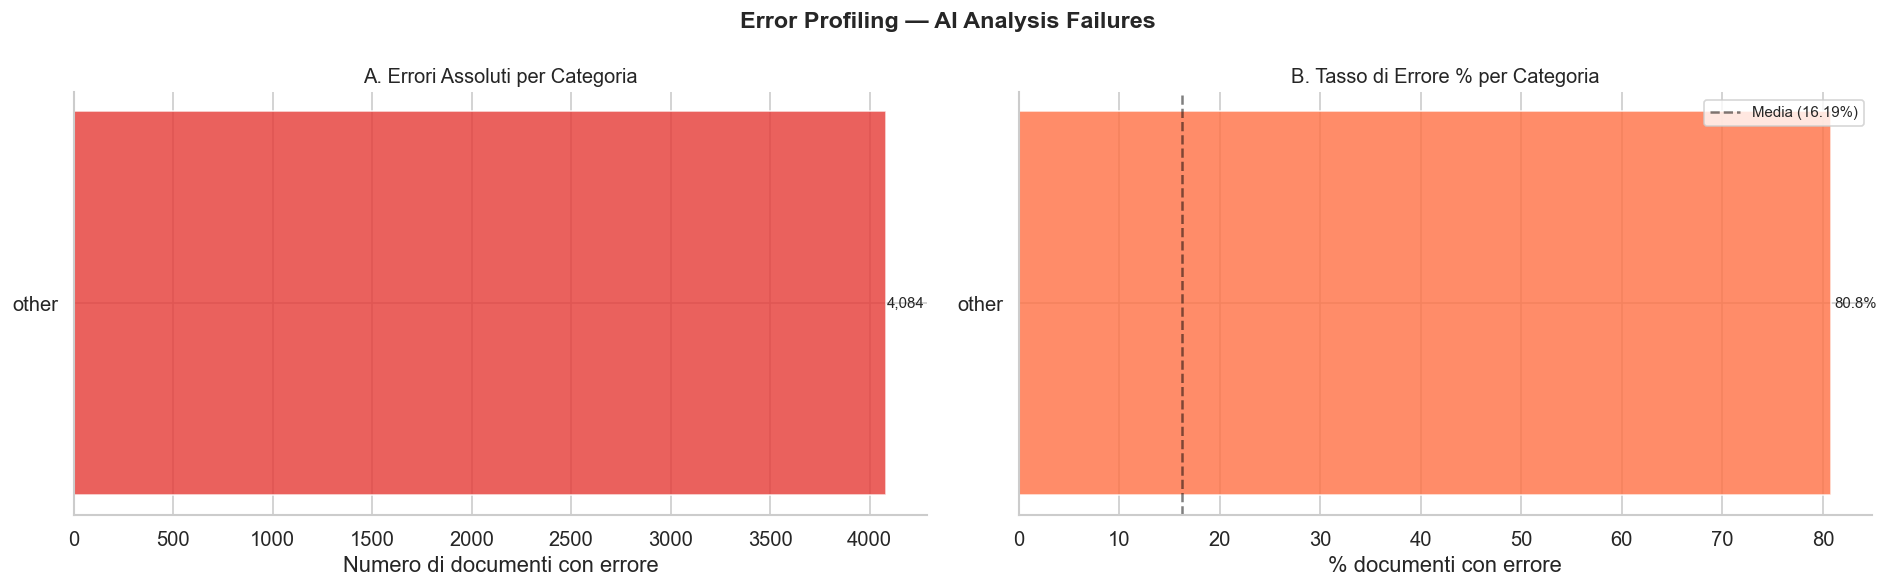

Triple da documenti con errore: 0 (0.00%)
-> Impatto sul grafo: trascurabile.


In [33]:
# ==============================================================================
# CELLA 3 — ERROR PROFILING: IMPATTO DEGLI ERRORI DI ANALISI AI
# ==============================================================================
# Domanda: gli errori AI sono uniformi tra le categorie documentali
# o colpiscono di piu' certi tipi (es. log tabulari)?

df_err_cat = pd.read_sql_query('''
    SELECT category, COUNT(*) AS error_count FROM documents
    WHERE error IS NOT NULL AND error != ''
    GROUP BY category ORDER BY error_count DESC
''', conn)

df_err_rate = pd.read_sql_query('''
    SELECT category, COUNT(*) AS total,
           SUM(CASE WHEN error IS NOT NULL AND error != '' THEN 1 END) AS errors
    FROM documents GROUP BY category
''', conn)
df_err_rate['error_rate'] = df_err_rate['errors'] / df_err_rate['total'] * 100
df_err_rate = df_err_rate.sort_values('error_rate', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Error Profiling — AI Analysis Failures', fontsize=14, fontweight='bold')

axes[0].barh(df_err_cat['category'], df_err_cat['error_count'],
             color='#E53935', alpha=0.8, edgecolor='white')
axes[0].set_title('A. Errori Assoluti per Categoria', fontsize=12)
axes[0].set_xlabel('Numero di documenti con errore')
for i,(_, row) in enumerate(df_err_cat.iterrows()):
    axes[0].text(row['error_count']+5, i, f"{row['error_count']:,}", va='center', fontsize=9)

axes[1].barh(df_err_rate['category'], df_err_rate['error_rate'],
             color='#FF7043', alpha=0.8, edgecolor='white')
axes[1].set_title('B. Tasso di Errore % per Categoria', fontsize=12)
axes[1].set_xlabel('% documenti con errore')
axes[1].axvline(x=16.19, color='black', linestyle='--', alpha=0.5, label='Media (16.19%)')
axes[1].legend(fontsize=9)
for i,(_, row) in enumerate(df_err_rate.iterrows()):
    axes[1].text(row['error_rate']+0.3, i, f"{row['error_rate']:.1f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

impacted = pd.read_sql_query('''
    SELECT COUNT(r.id) AS n FROM rdf_triples r
    JOIN documents d ON r.doc_id = d.doc_id
    WHERE d.error IS NOT NULL AND d.error != ''
''', conn).iloc[0,0]
total_t = pd.read_sql_query('SELECT COUNT(*) AS n FROM rdf_triples', conn).iloc[0,0]
print(f'Triple da documenti con errore: {impacted:,} ({impacted/total_t*100:.2f}%)')
msg = 'Impatto sul grafo: trascurabile.' if impacted == 0 else f'ATTENZIONE: {impacted:,} archi potenzialmente corrotti.'
print(f'-> {msg}')


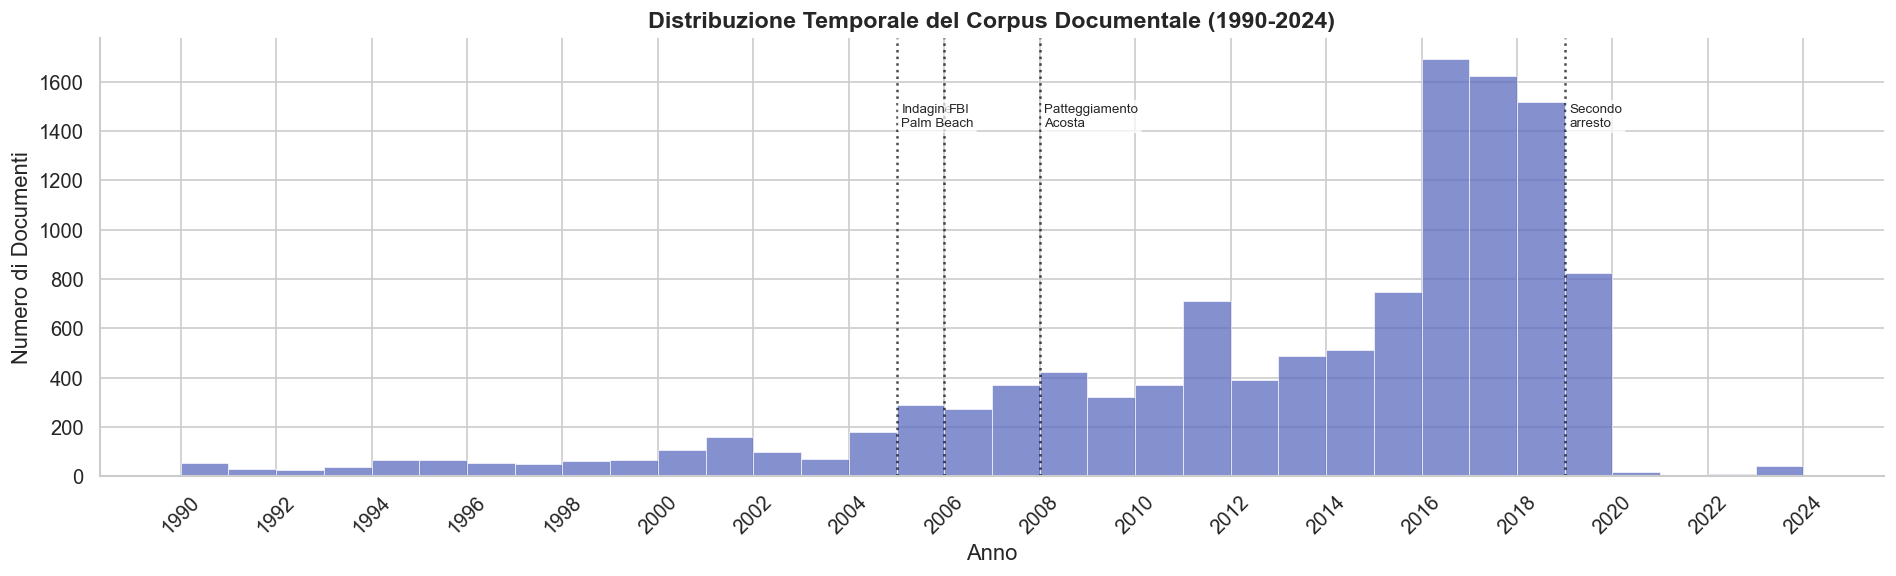

Documenti con anno identificabile: 11,733
Range: 1990 - 2024
Anno con piu' documenti: 2016


In [34]:
# ==============================================================================
# CELLA 4 — DISTRIBUZIONE TEMPORALE DEI DOCUMENTI
# ==============================================================================
# Visualizziamo quando sono stati prodotti i documenti nel corpus.
# I picchi temporali anticipano le epoche analitiche della RQ1.
# NOTA: questa e' la data dei *documenti*, non delle *interazioni* (triple).

JUDICIAL_EVENTS = {
    2005: 'Indagine\nPalm Beach',
    2006: 'FBI',
    2008: 'Patteggiamento\nAcosta',
    2019: 'Secondo\narresto'
}

df_dates = pd.read_sql_query("""
    SELECT date_range_earliest FROM documents
    WHERE date_range_earliest IS NOT NULL AND date_range_earliest != ''
""", conn)
df_dates['year'] = df_dates['date_range_earliest'].str.extract(r'(19\d{2}|20\d{2})')[0].astype(float)
df_dates = df_dates[(df_dates['year'] >= 1990) & (df_dates['year'] <= 2024)]

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_title('Distribuzione Temporale del Corpus Documentale (1990-2024)',
             fontsize=14, fontweight='bold')
ax.hist(df_dates['year'], bins=int(df_dates['year'].max()-df_dates['year'].min()),
        color='#5C6BC0', alpha=0.75, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Anno')
ax.set_ylabel('Numero di Documenti')
ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
plt.xticks(rotation=45)

for year, label in JUDICIAL_EVENTS.items():
    ax.axvline(x=year, color='black', linestyle=':', alpha=0.7, linewidth=1.5)
    ax.text(year+0.1, ax.get_ylim()[1]*0.85, label, fontsize=8, va='top',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()
print(f'Documenti con anno identificabile: {len(df_dates):,}')
print(f'Range: {int(df_dates["year"].min())} - {int(df_dates["year"].max())}')
print(f'Anno con piu\' documenti: {int(df_dates["year"].mode()[0])}')


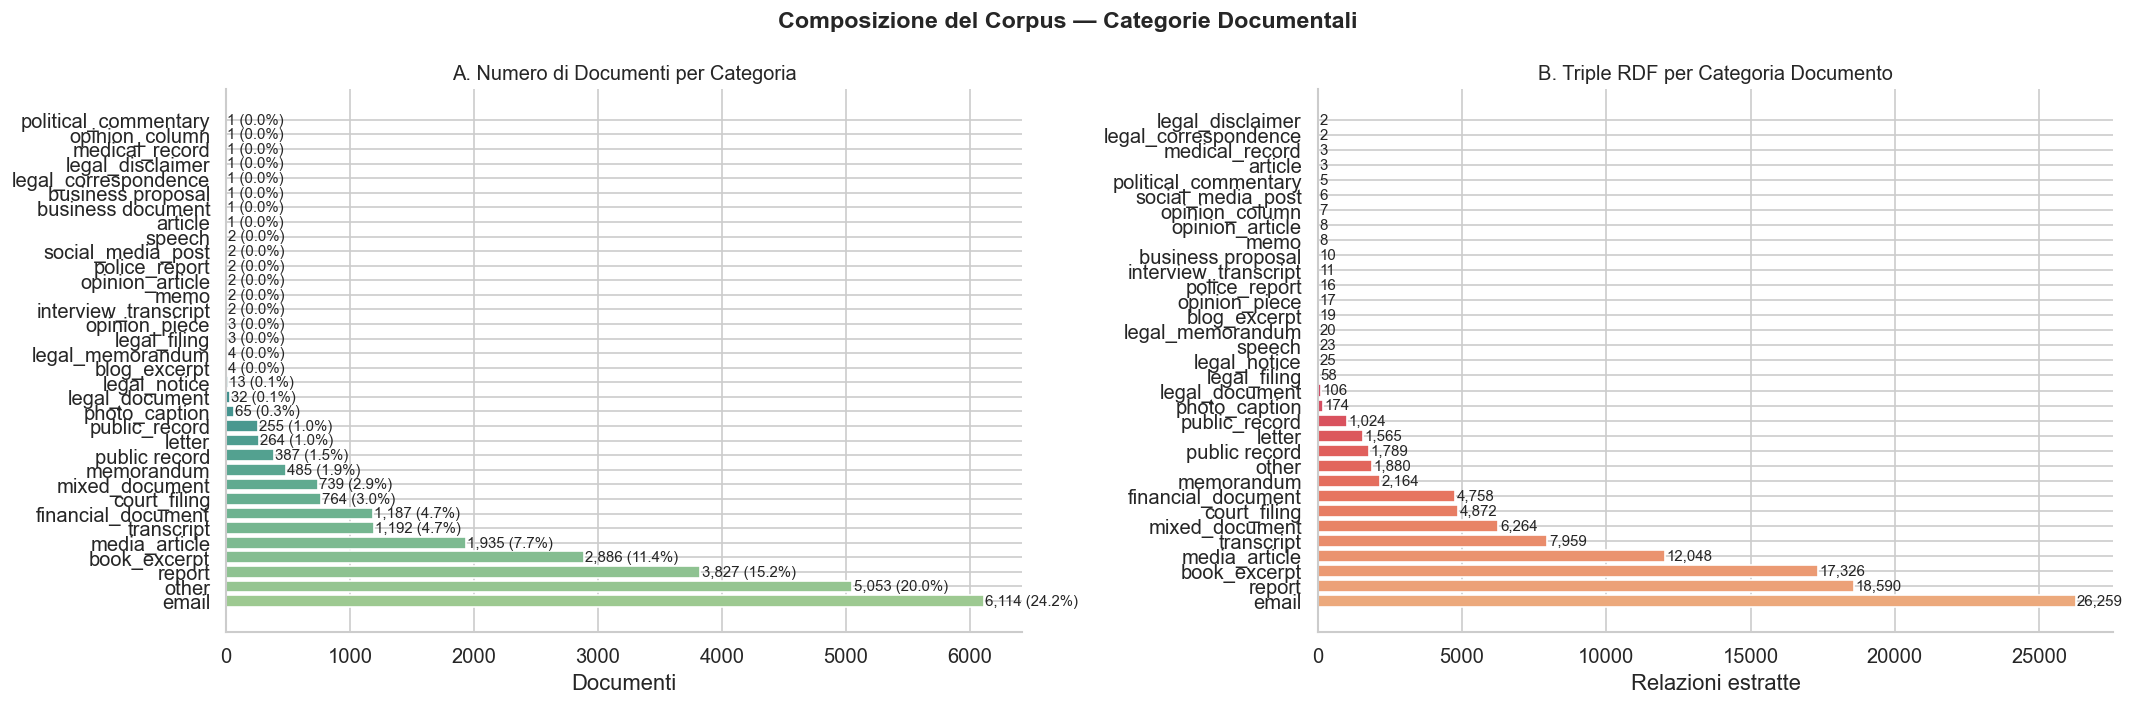

In [35]:
# ==============================================================================
# CELLA 5 — CATEGORIE DOCUMENTALI & TRIPLE PER CATEGORIA
# ==============================================================================
# Mappa la composizione del corpus. Cruciale per interpretare i risultati NLP:
# se il corpus e' dominato da documenti legali, la prevalenza di Legal
# nella classificazione zero-shot e' attesa, non sorprendente.

df_cat = pd.read_sql_query("""
    SELECT category, COUNT(*) AS doc_count
    FROM documents GROUP BY category ORDER BY doc_count DESC
""", conn)

df_cat_t = pd.read_sql_query("""
    SELECT d.category, COUNT(r.id) AS triple_count
    FROM rdf_triples r JOIN documents d ON r.doc_id = d.doc_id
    GROUP BY d.category ORDER BY triple_count DESC
""", conn)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Composizione del Corpus — Categorie Documentali', fontsize=14, fontweight='bold')

pal_c = sns.color_palette('crest', len(df_cat))
axes[0].barh(df_cat['category'], df_cat['doc_count'], color=pal_c, edgecolor='white')
axes[0].set_title('A. Numero di Documenti per Categoria', fontsize=12)
axes[0].set_xlabel('Documenti')
total_d = df_cat['doc_count'].sum()
for i,(_, row) in enumerate(df_cat.iterrows()):
    axes[0].text(row['doc_count']+10, i,
                 f"{row['doc_count']:,} ({row['doc_count']/total_d*100:.1f}%)",
                 va='center', fontsize=9)

pal_t = sns.color_palette('flare', len(df_cat_t))
axes[1].barh(df_cat_t['category'], df_cat_t['triple_count'], color=pal_t, edgecolor='white')
axes[1].set_title('B. Triple RDF per Categoria Documento', fontsize=12)
axes[1].set_xlabel('Relazioni estratte')
for i,(_, row) in enumerate(df_cat_t.iterrows()):
    axes[1].text(row['triple_count']+50, i, f"{row['triple_count']:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


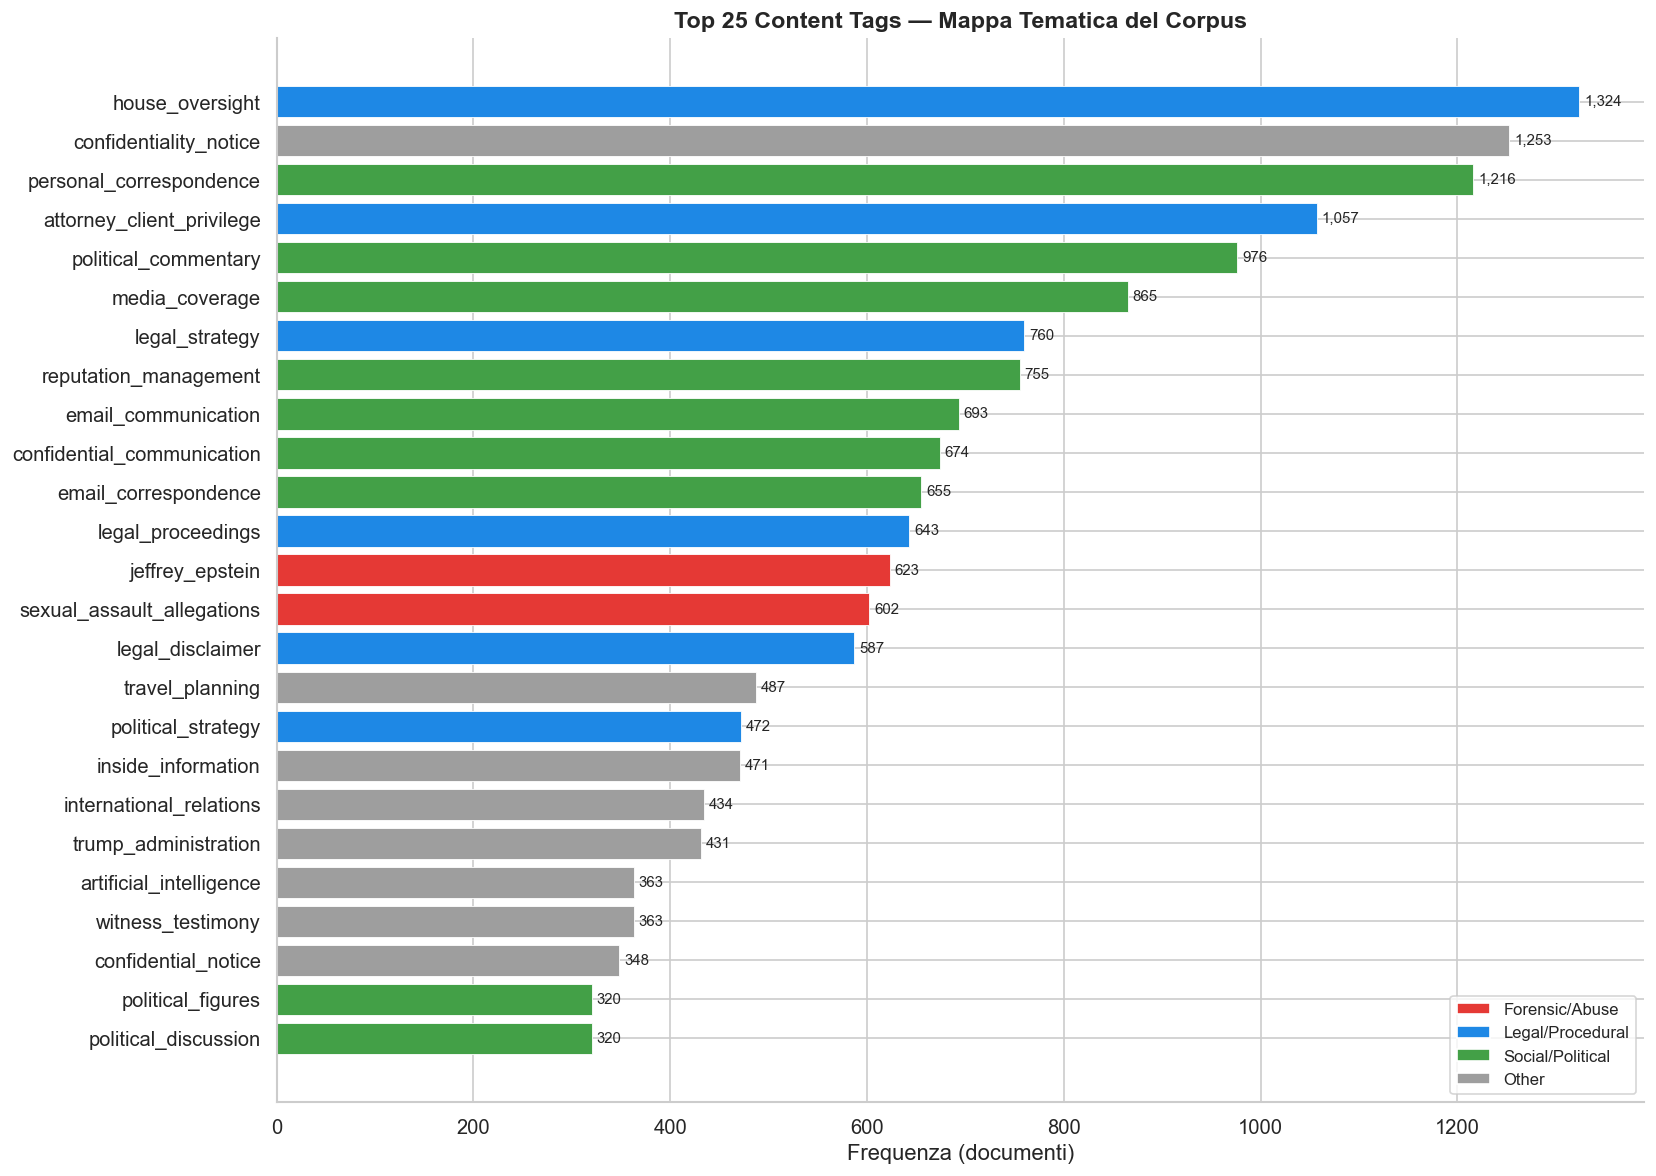

In [36]:
# ==============================================================================
# CELLA 6 — CONTENT TAGS: MAPPA TEMATICA DEL CORPUS
# ==============================================================================
# I content tags sono etichette semantiche AI per ogni documento.
# sexual_assault_allegations, attorney_client_privilege, house_oversight
# nelle top posizioni confermano la rilevanza del corpus per le RQ.
# Coloriamo per macro-categoria per anticipare la distribuzione NLP.

df_tags_raw = pd.read_sql_query("""
    SELECT content_tags FROM documents
    WHERE content_tags IS NOT NULL AND content_tags != ''
""", conn)
all_tags = []
for _, row in df_tags_raw.iterrows():
    try:
        all_tags.extend([t.lower().strip() for t in json.loads(row['content_tags'])])
    except: continue

df_tags = pd.Series(all_tags).value_counts().head(25).reset_index()
df_tags.columns = ['tag','count']

def tag_color(tag):
    forensic = ['epstein','assault','sexual','victim','trafficking','abuse']
    legal    = ['legal','court','attorney','privilege','proceedings','strategy',
                'disclaimer','subpoena','investigat','oversight']
    social   = ['correspondence','communication','personal','political','commentary',
                'media','reput','email']
    if any(k in tag for k in forensic): return '#E53935'
    if any(k in tag for k in legal):    return '#1E88E5'
    if any(k in tag for k in social):   return '#43A047'
    return '#9E9E9E'

colors = [tag_color(t) for t in df_tags['tag']]

fig, ax = plt.subplots(figsize=(14, 10))
ax.barh(df_tags['tag'][::-1], df_tags['count'][::-1],
        color=colors[::-1], edgecolor='white', linewidth=0.5)
ax.set_title('Top 25 Content Tags — Mappa Tematica del Corpus', fontsize=14, fontweight='bold')
ax.set_xlabel('Frequenza (documenti)')
for i,(_, row) in enumerate(df_tags.iterrows()):
    ax.text(row['count']+5, len(df_tags)-1-i, f"{row['count']:,}", va='center', fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#E53935', label='Forensic/Abuse'),
    Patch(facecolor='#1E88E5', label='Legal/Procedural'),
    Patch(facecolor='#43A047', label='Social/Political'),
    Patch(facecolor='#9E9E9E', label='Other'),
], loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


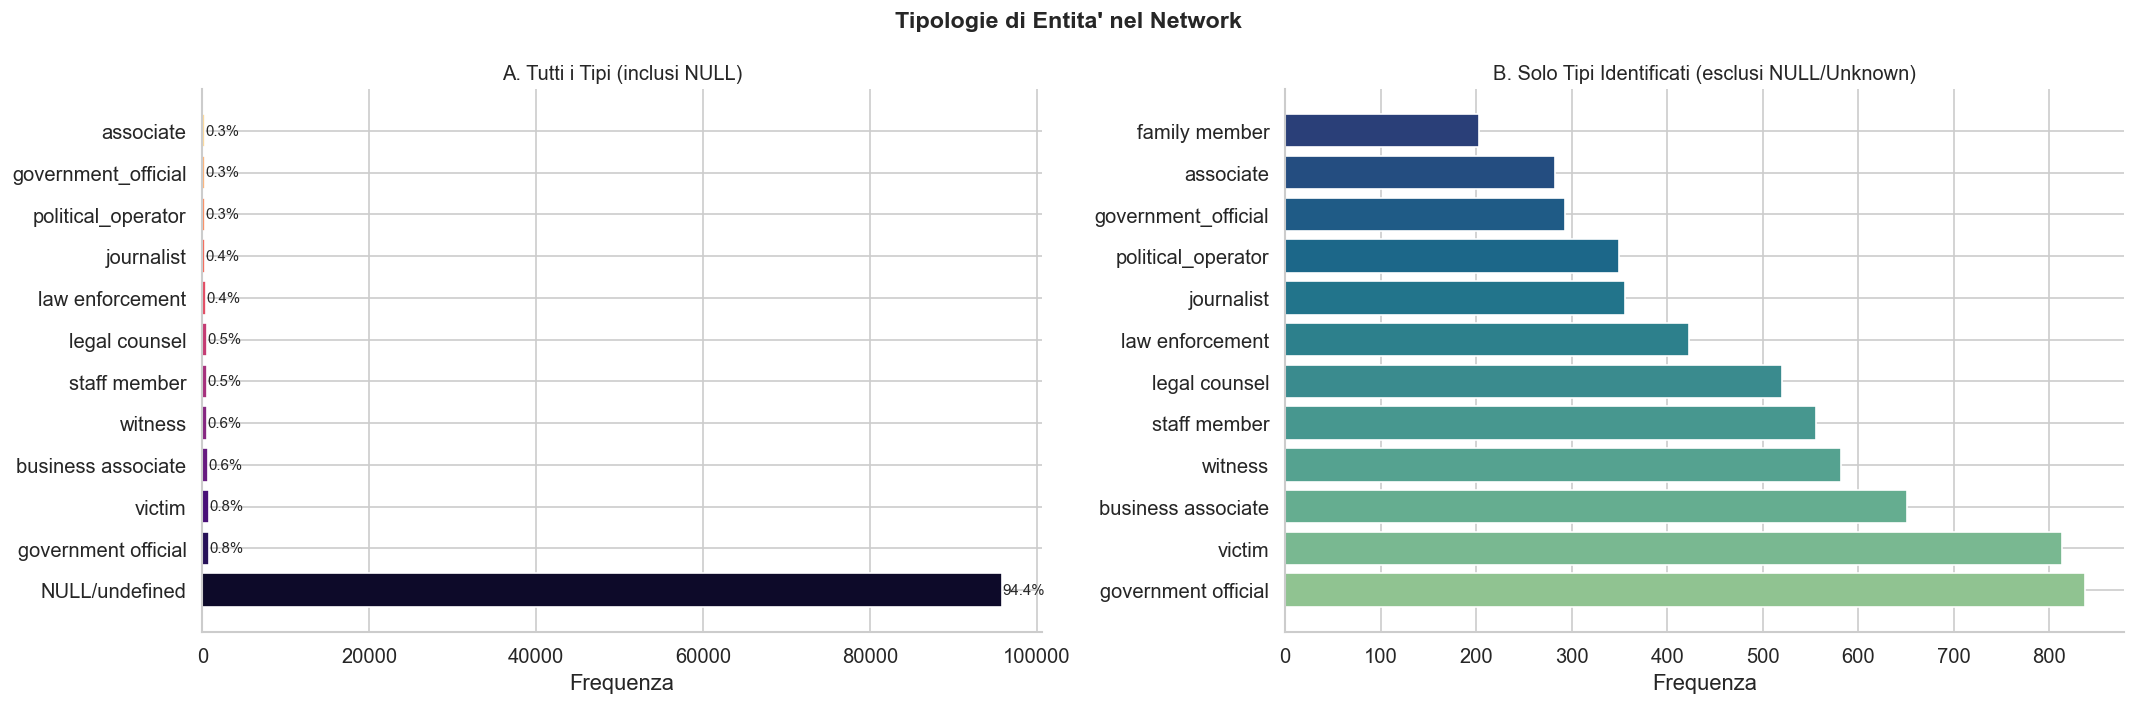

Attori unici nel dataset: 19,659


In [37]:
# ==============================================================================
# CELLA 7 — TIPOLOGIE DI ENTITA' (ACTOR TYPES)
# ==============================================================================
# Qual e' la composizione ontologica del network?
# Il confronto con/senza NULL rivela l'estensione del problema
# di non-identificazione delle entita' — rilevante per RQ2.

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Tipologie di Entita\' nel Network', fontsize=14, fontweight='bold')

df_all = pd.read_sql_query("""
    SELECT COALESCE(actor_likely_type, 'NULL/undefined') AS tipo, COUNT(*) AS count
    FROM rdf_triples GROUP BY tipo ORDER BY count DESC LIMIT 12
""", conn)
axes[0].barh(df_all['tipo'], df_all['count'],
             color=sns.color_palette('magma', len(df_all)), edgecolor='white')
axes[0].set_title('A. Tutti i Tipi (inclusi NULL)', fontsize=12)
axes[0].set_xlabel('Frequenza')
for i,(_, row) in enumerate(df_all.iterrows()):
    pct = row['count']/df_all['count'].sum()*100
    axes[0].text(row['count']+50, i, f'{pct:.1f}%', va='center', fontsize=9)

df_clean = pd.read_sql_query("""
    SELECT actor_likely_type AS tipo, COUNT(*) AS count
    FROM rdf_triples
    WHERE actor_likely_type IS NOT NULL
      AND LOWER(actor_likely_type) NOT IN ('unknown','null/undefined','undefined')
    GROUP BY tipo ORDER BY count DESC LIMIT 12
""", conn)
axes[1].barh(df_clean['tipo'], df_clean['count'],
             color=sns.color_palette('crest', len(df_clean)), edgecolor='white')
axes[1].set_title('B. Solo Tipi Identificati (esclusi NULL/Unknown)', fontsize=12)
axes[1].set_xlabel('Frequenza')

plt.tight_layout()
plt.show()
n_actors = pd.read_sql_query('SELECT COUNT(DISTINCT actor) AS n FROM rdf_triples', conn).iloc[0,0]
print(f'Attori unici nel dataset: {n_actors:,}')


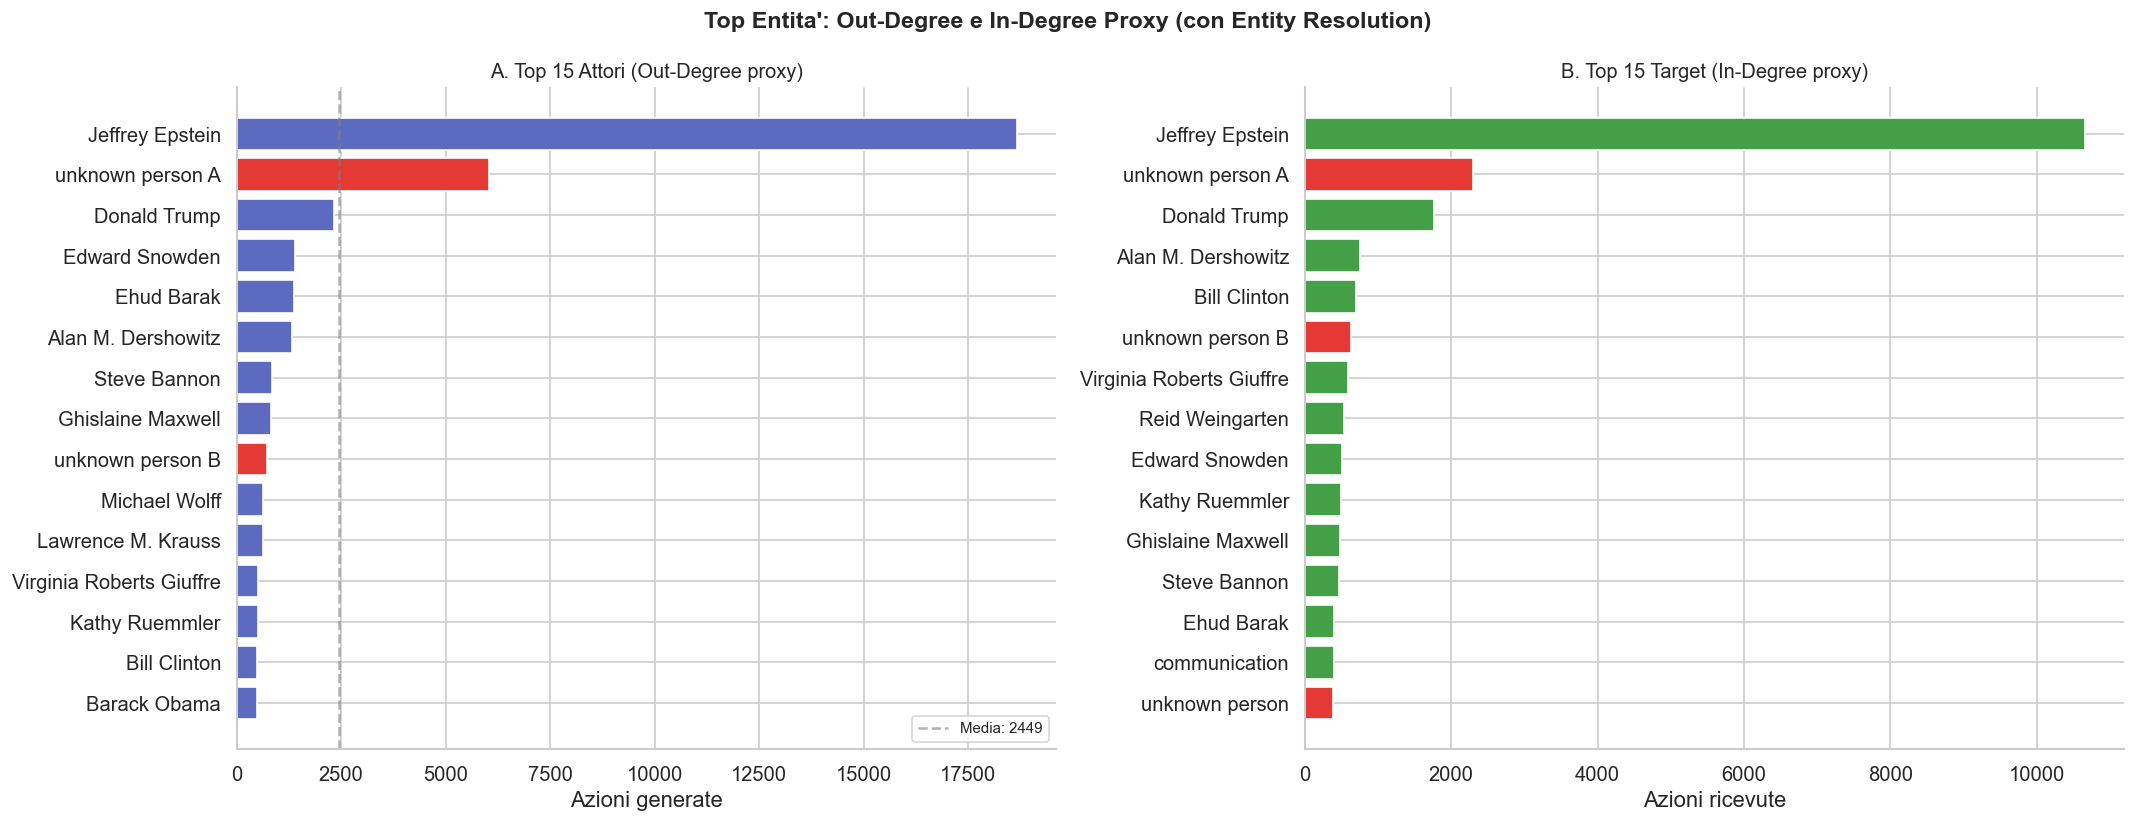

Nota: barre rosse = entita' Unknown. Confermano la rilevanza per la RQ2.


In [38]:
# ==============================================================================
# CELLA 8 — TOP ATTORI E TARGET (PRE-RQ2)
# ==============================================================================
# Chi genera piu' azioni (Out-Degree proxy) e chi le riceve (In-Degree)?
# Le barre rosse segnalano entita' Unknown — gia' visibili tra i top.
# Anticipa la RQ2: gli Unknown non sono marginali nel network.

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top Entita\': Out-Degree e In-Degree Proxy (con Entity Resolution)',
             fontsize=14, fontweight='bold')

df_actors = pd.read_sql_query("""
    SELECT COALESCE(e.canonical_name, r.actor) AS entita, COUNT(*) AS count
    FROM rdf_triples r
    LEFT JOIN entity_aliases e ON r.actor = e.original_name
    GROUP BY entita ORDER BY count DESC LIMIT 15
""", conn)
pal_a = ['#E53935' if 'unknown' in str(n).lower() else '#5C6BC0' for n in df_actors['entita']]
axes[0].barh(df_actors['entita'][::-1], df_actors['count'][::-1], color=pal_a[::-1], edgecolor='white')
axes[0].set_title('A. Top 15 Attori (Out-Degree proxy)', fontsize=12)
axes[0].set_xlabel('Azioni generate')
axes[0].axvline(df_actors['count'].mean(), color='gray', linestyle='--', alpha=0.6,
                label=f"Media: {df_actors['count'].mean():.0f}")
axes[0].legend(fontsize=9)

df_targets = pd.read_sql_query("""
    SELECT COALESCE(e.canonical_name, r.target) AS entita, COUNT(*) AS count
    FROM rdf_triples r
    LEFT JOIN entity_aliases e ON r.target = e.original_name
    GROUP BY entita ORDER BY count DESC LIMIT 15
""", conn)
pal_t = ['#E53935' if 'unknown' in str(n).lower() else '#43A047' for n in df_targets['entita']]
axes[1].barh(df_targets['entita'][::-1], df_targets['count'][::-1], color=pal_t[::-1], edgecolor='white')
axes[1].set_title('B. Top 15 Target (In-Degree proxy)', fontsize=12)
axes[1].set_xlabel('Azioni ricevute')

plt.tight_layout()
plt.show()
print('Nota: barre rosse = entita\' Unknown. Confermano la rilevanza per la RQ2.')


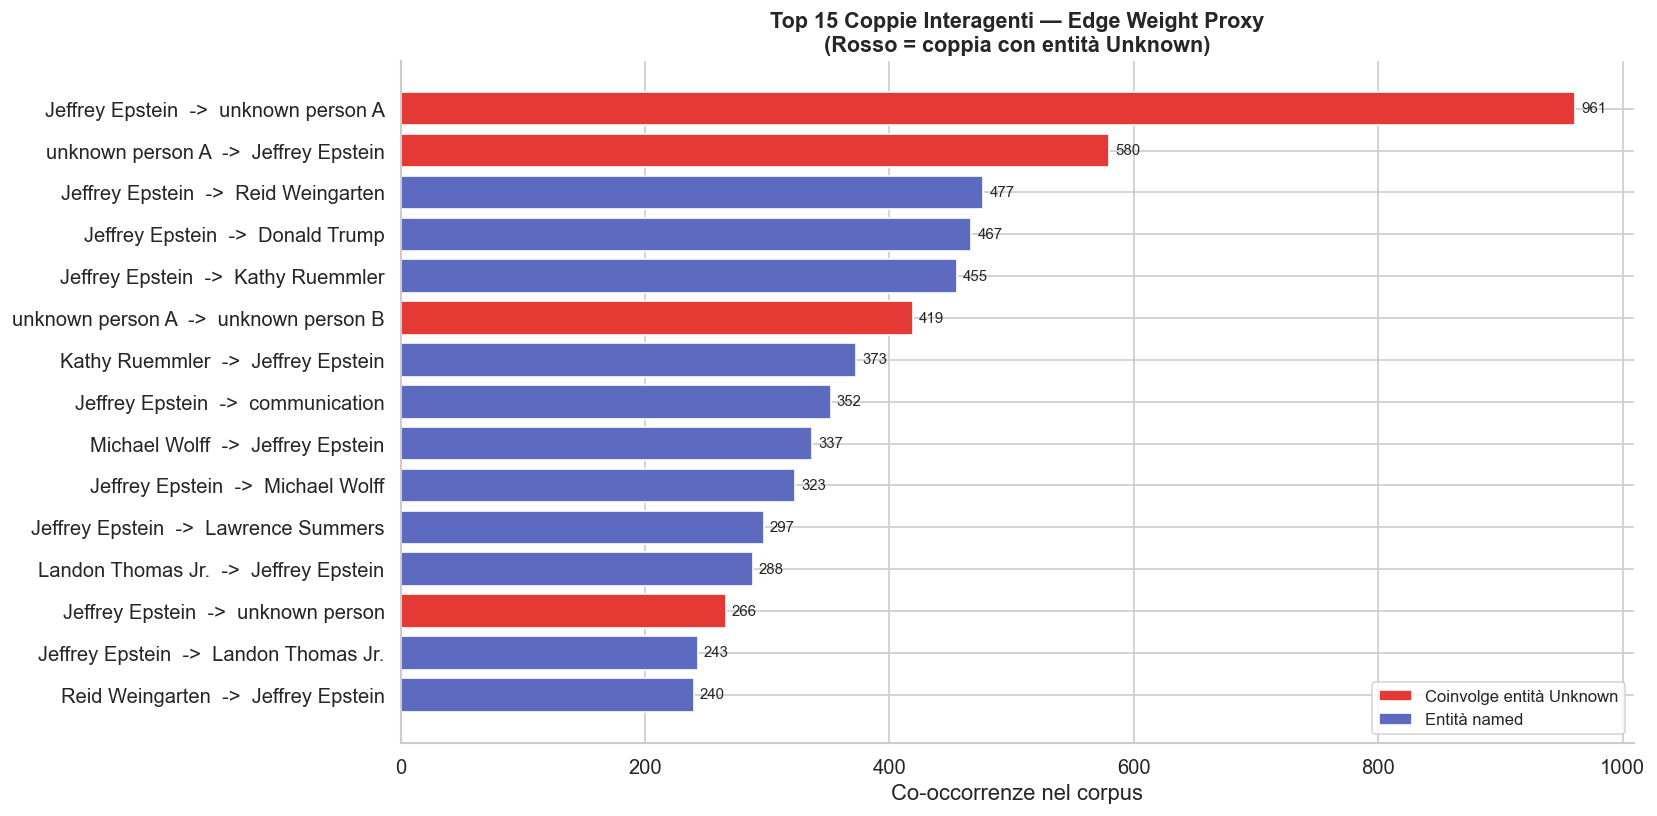

Coppie con Unknown nelle top 15: 4/15


In [39]:
# ==============================================================================
# CELLA 9 — TOP COPPIE INTERAGENTI (EDGE WEIGHT PROXY)
# ==============================================================================
# Quali sono le relazioni più frequenti nel corpus?
# Usiamo la stessa UNKNOWN_PATTERN della cella 9 per colorare
# correttamente le coppie che coinvolgono entità anonime.

df_pairs = pd.read_sql_query("""
    SELECT
        COALESCE(ea.canonical_name, r.actor) || '  ->  ' ||
        COALESCE(et.canonical_name, r.target) AS coppia,
        COALESCE(ea.canonical_name, r.actor)  AS actor_resolved,
        COALESCE(et.canonical_name, r.target) AS target_resolved,
        COUNT(*) AS count
    FROM rdf_triples r
    LEFT JOIN entity_aliases ea ON r.actor  = ea.original_name
    LEFT JOIN entity_aliases et ON r.target = et.original_name
    GROUP BY coppia ORDER BY count DESC LIMIT 15
""", conn)

UNKNOWN_PATTERN_BROAD = re.compile(
    r'\b(unknown|jane doe|john doe|individual\s*#?\d*|victim\s*#?\d*|'
    r'minor\s*#?\d*|girl\s*#?\d*|unidentified|'
    r'unknown\s+person\s*[a-z0-9]*)\b',
    re.IGNORECASE
)

def coppia_has_unknown(row):
    return (
        bool(UNKNOWN_PATTERN_BROAD.search(str(row['actor_resolved']))) or
        bool(UNKNOWN_PATTERN_BROAD.search(str(row['target_resolved'])))
    )

df_pairs['has_unknown'] = df_pairs.apply(coppia_has_unknown, axis=1)
colors = ['#E53935' if v else '#5C6BC0' for v in df_pairs['has_unknown']]

fig, ax = plt.subplots(figsize=(14, 7))
ax.barh(df_pairs['coppia'][::-1], df_pairs['count'][::-1],
        color=colors[::-1], edgecolor='white')
ax.set_title('Top 15 Coppie Interagenti — Edge Weight Proxy\n'
             '(Rosso = coppia con entità Unknown)', fontsize=13, fontweight='bold')
ax.set_xlabel('Co-occorrenze nel corpus')
for i,(_, row) in enumerate(df_pairs.iterrows()):
    ax.text(row['count']+5, len(df_pairs)-1-i, f"{row['count']:,}", va='center', fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#E53935', label='Coinvolge entità Unknown'),
    Patch(facecolor='#5C6BC0', label='Entità named'),
], fontsize=10)

plt.tight_layout()
plt.show()

n_unk_pairs = df_pairs['has_unknown'].sum()
print(f"Coppie con Unknown nelle top 15: {n_unk_pairs}/15")

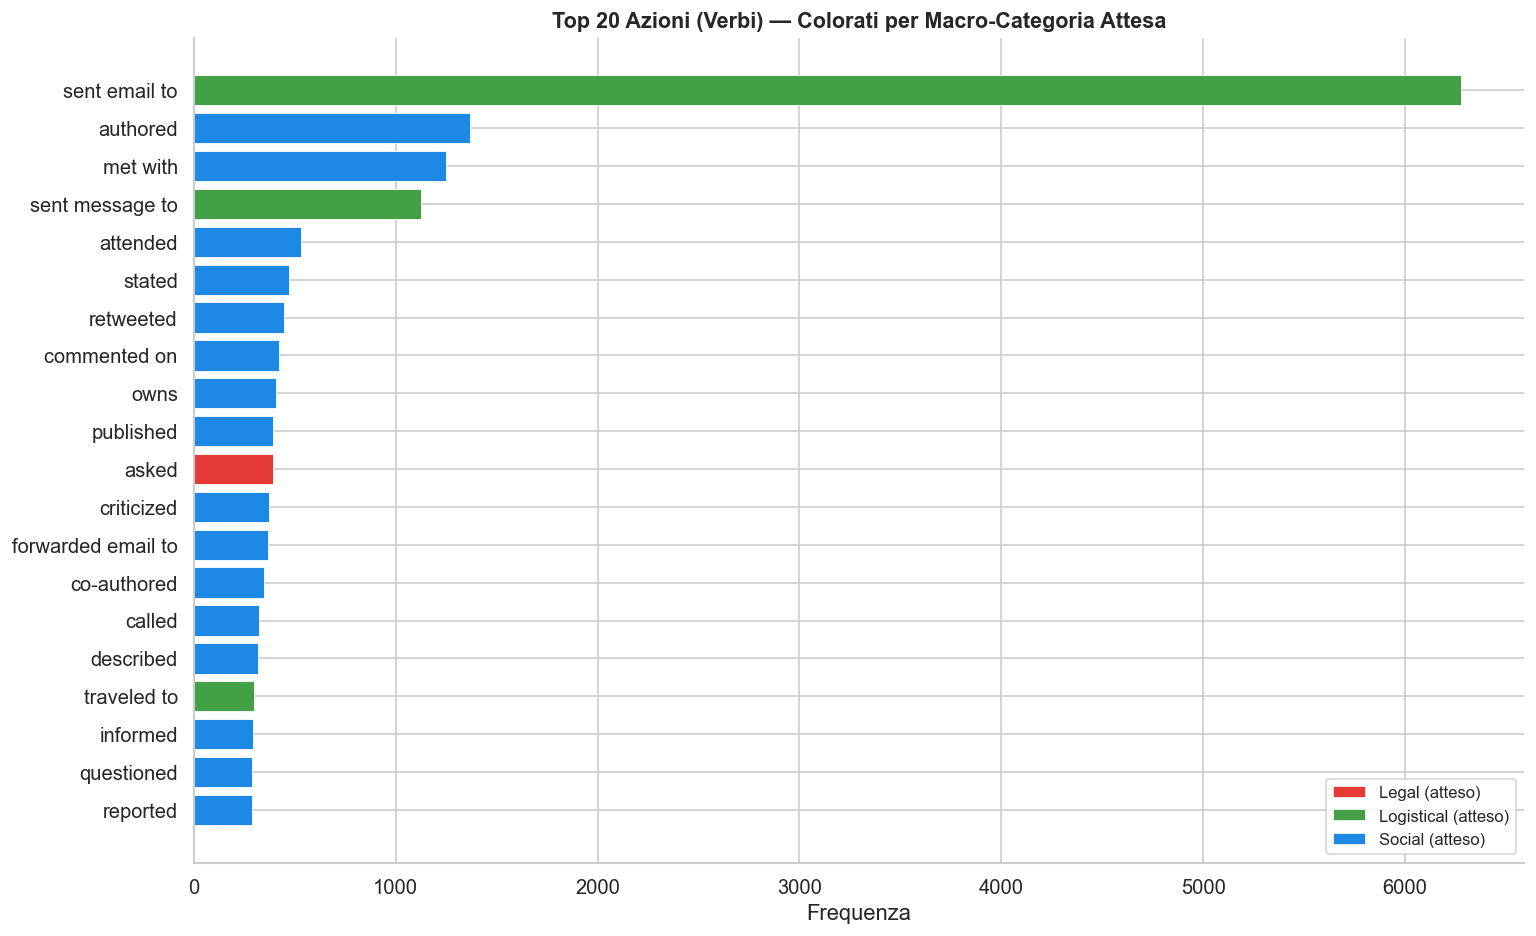

In [40]:
# ==============================================================================
# CELLA 10 — VOCABOLARIO RELAZIONALE: I VERBI DEL NETWORK
# ==============================================================================
# I verbi delle triple RDF definiscono la semantica delle relazioni.
# Colorati per macro-categoria attesa (Legal/Social/Logistical),
# anticipano se il modello BART trovera' materiale disambiguante.

df_verbs = pd.read_sql_query("""
    SELECT action, COUNT(*) AS count
    FROM rdf_triples WHERE action IS NOT NULL AND action != ''
    GROUP BY action ORDER BY count DESC LIMIT 20
""", conn)

def verb_color(v):
    legal_kw = ['filed','testified','alleged','charged','convicted','subpoena',
                'settled','pleaded','indicted','prosecuted','denied','ruled','asked','requested']
    log_kw   = ['traveled','flew','transported','sent','received','paid','visited',
                'booked','arrived','departed','escorted','emailed']
    if any(k in v.lower() for k in legal_kw): return '#E53935'
    if any(k in v.lower() for k in log_kw):   return '#43A047'
    return '#1E88E5'

colors = [verb_color(v) for v in df_verbs['action']]

fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(df_verbs['action'][::-1], df_verbs['count'][::-1],
        color=colors[::-1], edgecolor='white', linewidth=0.5)
ax.set_title('Top 20 Azioni (Verbi) — Colorati per Macro-Categoria Attesa',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Frequenza')
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#E53935', label='Legal (atteso)'),
    Patch(facecolor='#43A047', label='Logistical (atteso)'),
    Patch(facecolor='#1E88E5', label='Social (atteso)'),
], fontsize=10)
plt.tight_layout()
plt.show()


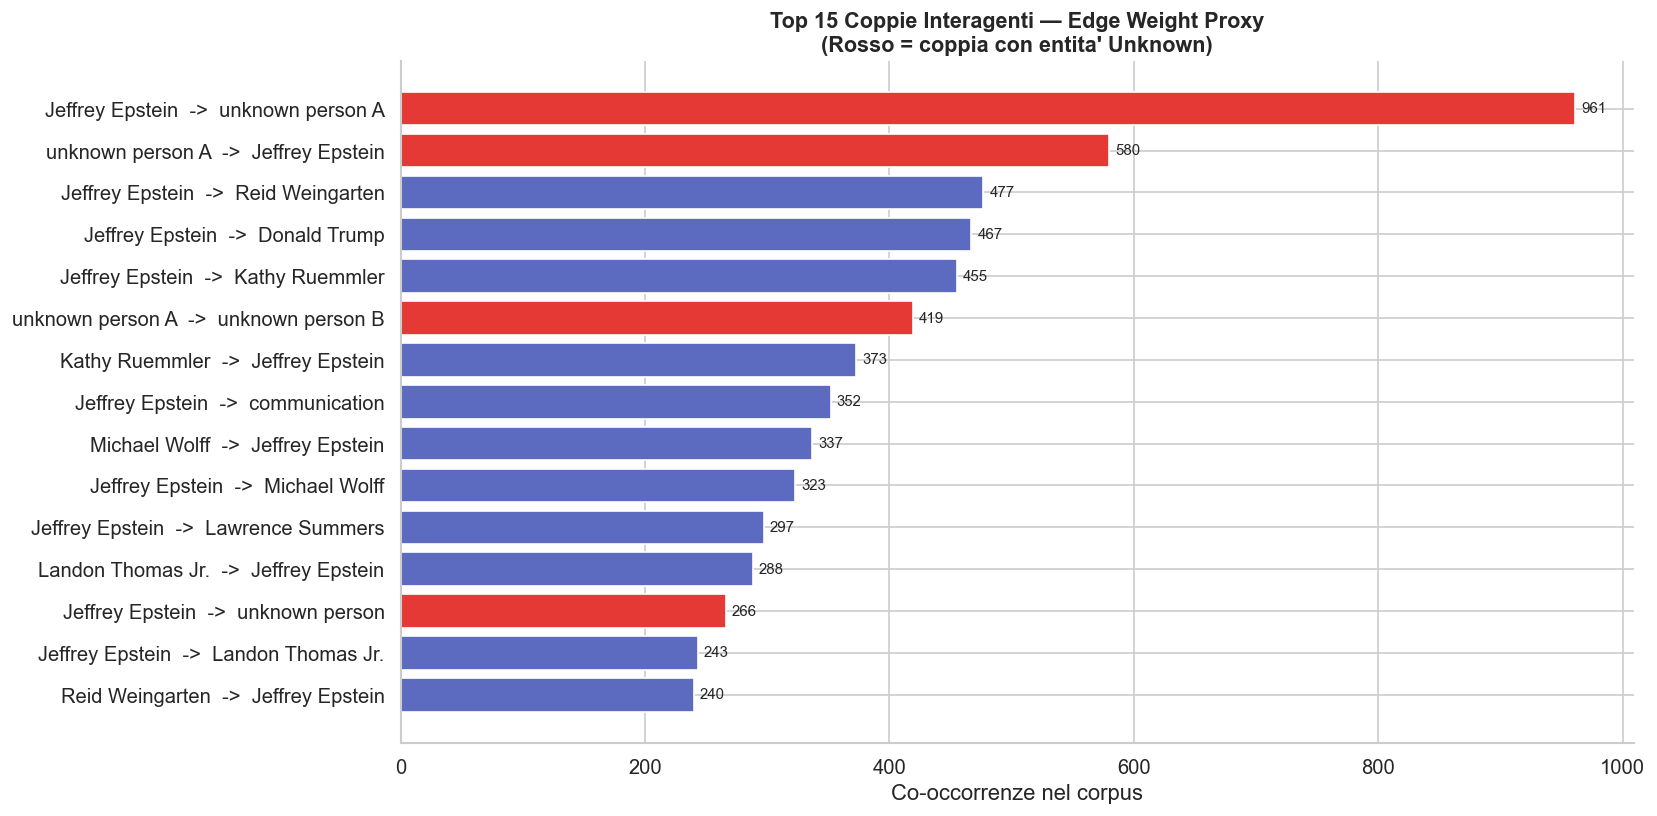

In [41]:
# ==============================================================================
# CELLA 11 — TOP COPPIE INTERAGENTI (EDGE WEIGHT PROXY)
# ==============================================================================
# Quali sono le relazioni piu' frequenti nel corpus?
# Anticipano la struttura ego-centrica del network (hub: Epstein).
# Le coppie con entita' Unknown (in rosso) anticipano la RQ2.

df_pairs = pd.read_sql_query("""
    SELECT
        COALESCE(ea.canonical_name, r.actor) || '  ->  ' ||
        COALESCE(et.canonical_name, r.target) AS coppia,
        COUNT(*) AS count
    FROM rdf_triples r
    LEFT JOIN entity_aliases ea ON r.actor  = ea.original_name
    LEFT JOIN entity_aliases et ON r.target = et.original_name
    GROUP BY coppia ORDER BY count DESC LIMIT 15
""", conn)

colors = ['#E53935' if 'unknown' in str(p).lower() else '#5C6BC0'
          for p in df_pairs['coppia']]

fig, ax = plt.subplots(figsize=(14, 7))
ax.barh(df_pairs['coppia'][::-1], df_pairs['count'][::-1],
        color=colors[::-1], edgecolor='white')
ax.set_title('Top 15 Coppie Interagenti — Edge Weight Proxy\n'
             '(Rosso = coppia con entita\' Unknown)', fontsize=13, fontweight='bold')
ax.set_xlabel('Co-occorrenze nel corpus')
for i,(_, row) in enumerate(df_pairs.iterrows()):
    ax.text(row['count']+5, len(df_pairs)-1-i, f"{row['count']:,}", va='center', fontsize=9)
plt.tight_layout()
plt.show()


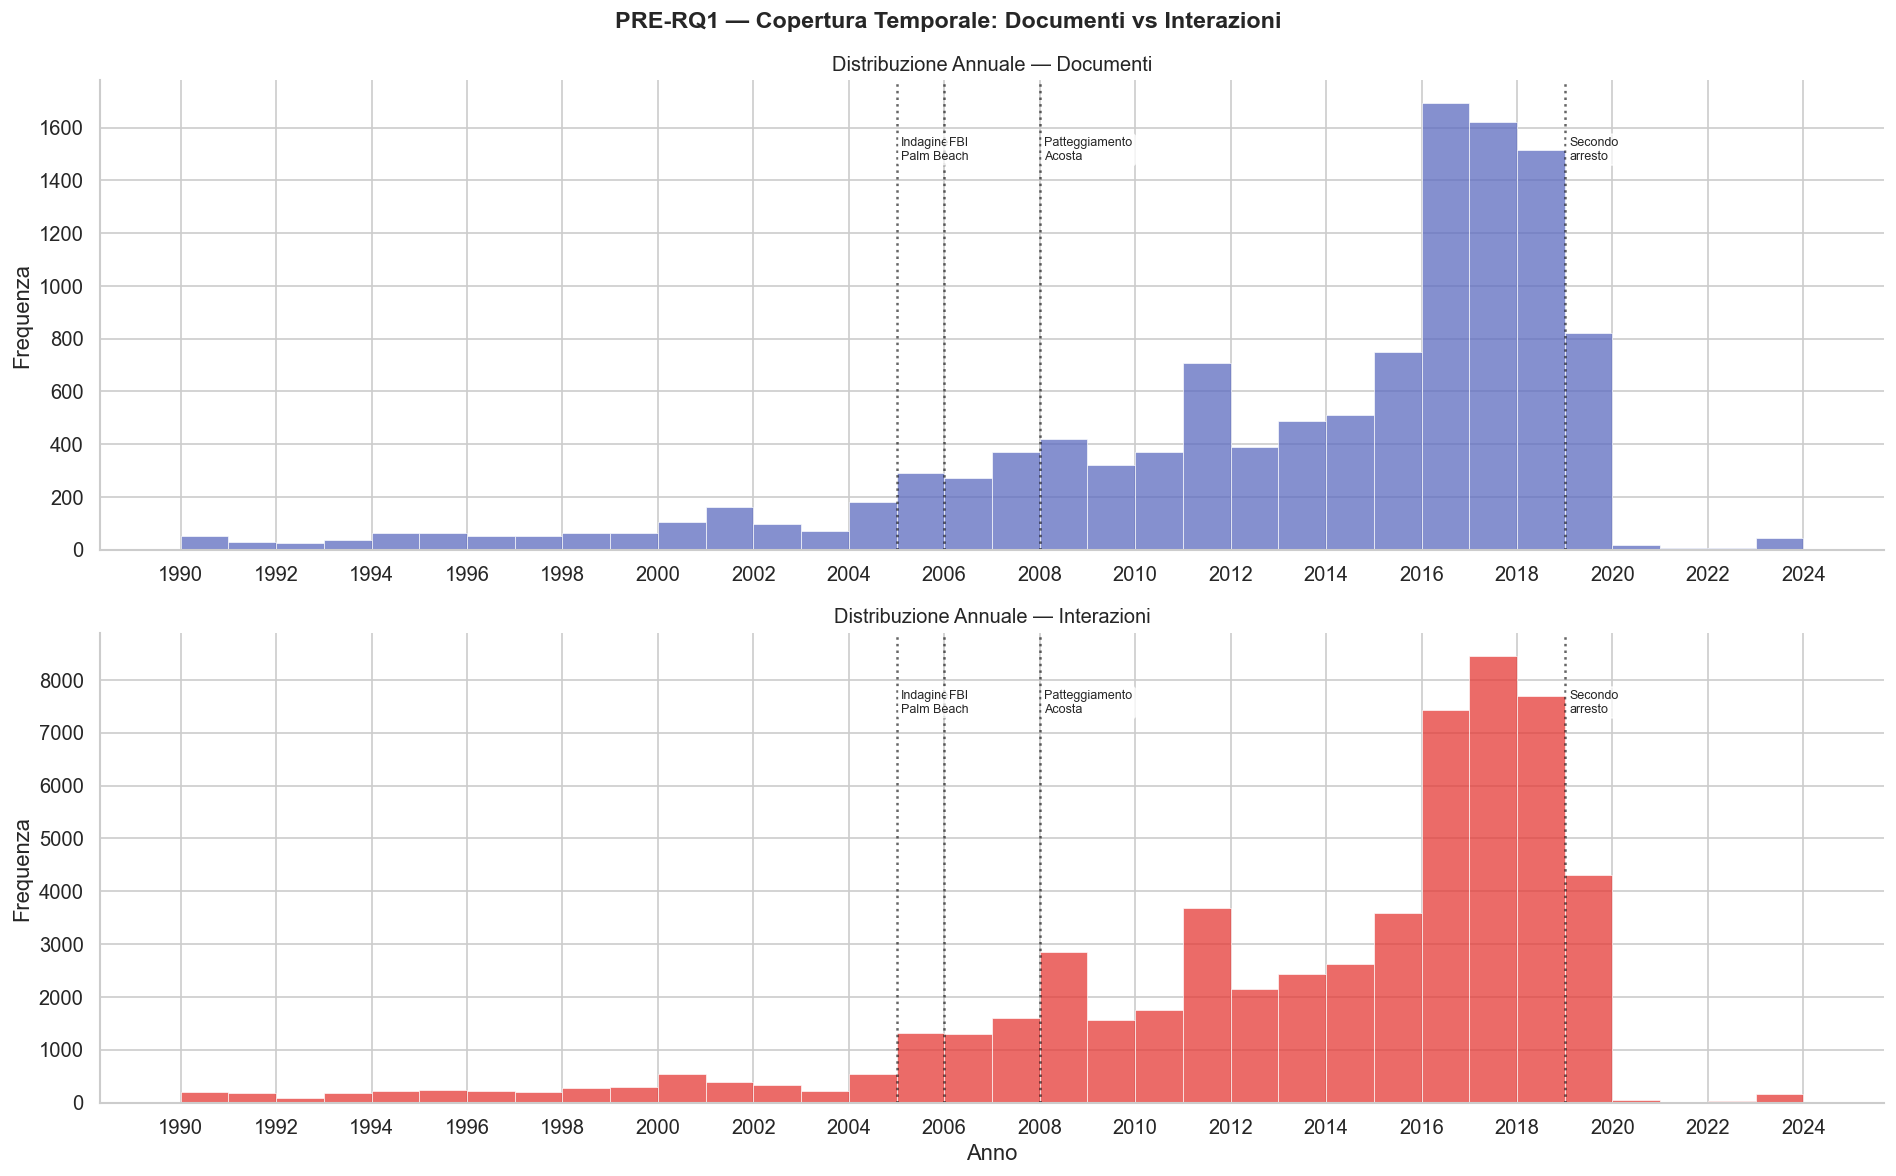

Triple con anno identificabile: 57,084 / 107,030 (53.3%)
NOTA: per RQ1 useremo la data del documento come proxy per le triple senza timestamp.


In [42]:
# ==============================================================================
# CELLA 12 — PRE-RQ1: COPERTURA TEMPORALE DELLE TRIPLE
# ==============================================================================
# Diversamente dalla cella 4 (date dei documenti), qui analizziamo la
# distribuzione temporale delle *interazioni* (triple RDF).
# E' il dato diretto per la RQ1, ma il 42% di timestamp mancanti
# limita l'analisi longitudinale — da dichiarare nella metodologia.

df_tt = pd.read_sql_query("""
    SELECT timestamp FROM rdf_triples
    WHERE timestamp IS NOT NULL AND timestamp != ''
""", conn)
df_tt['year'] = df_tt['timestamp'].astype(str).str.extract(r'(19\d{2}|20\d{2})')[0].astype(float)
df_tt = df_tt[(df_tt['year']>=1990)&(df_tt['year']<=2024)]

df_dd = pd.read_sql_query("""
    SELECT date_range_earliest FROM documents WHERE date_range_earliest IS NOT NULL
""", conn)
df_dd['year'] = df_dd['date_range_earliest'].str.extract(r'(19\d{2}|20\d{2})')[0].astype(float)
df_dd = df_dd[(df_dd['year']>=1990)&(df_dd['year']<=2024)]

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle('PRE-RQ1 — Copertura Temporale: Documenti vs Interazioni',
             fontsize=14, fontweight='bold')

for ax, data, label, color in [
    (axes[0], df_dd['year'],  'Documenti',   '#5C6BC0'),
    (axes[1], df_tt['year'],  'Interazioni', '#E53935'),
]:
    ax.hist(data, bins=range(1990,2025), color=color, alpha=0.75, edgecolor='white', linewidth=0.5)
    ax.set_title(f'Distribuzione Annuale — {label}', fontsize=12)
    ax.set_ylabel('Frequenza')
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
    for year, lbl in JUDICIAL_EVENTS.items():
        ax.axvline(x=year, color='black', linestyle=':', alpha=0.6)
        ax.text(year+0.1, ax.get_ylim()[1]*0.88, lbl, fontsize=7.5, va='top',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

axes[1].set_xlabel('Anno')
plt.tight_layout()
plt.show()

total_t = pd.read_sql_query('SELECT COUNT(*) AS n FROM rdf_triples', conn).iloc[0,0]
print(f'Triple con anno identificabile: {len(df_tt):,} / {total_t:,} ({len(df_tt)/total_t*100:.1f}%)')
print(f'NOTA: per RQ1 useremo la data del documento come proxy per le triple senza timestamp.')


In [43]:
# ==============================================================================
# CELLA 13 — GENERAZIONE DEL DATASET MASTER (edges_base.csv)
# ==============================================================================
# Uniamo triple + metadati documentali in un unico DataFrame.
# Entity Resolution applicata via COALESCE con entity_aliases.
# Strategia timestamp: usa la tripla se disponibile, doc come fallback.
# Questo CSV e' l'input del Notebook 02 (NLP Zero-Shot Classification).

print('Generazione dataset master in corso...')

df_master = pd.read_sql_query("""
SELECT
    r.id                                               AS edge_id,
    COALESCE(ea_a.canonical_name, r.actor)             AS actor,
    r.action,
    COALESCE(ea_t.canonical_name, r.target)            AS target,
    r.timestamp                                         AS interaction_time,
    r.location,
    r.actor_likely_type,
    d.category                                          AS doc_category,
    d.date_range_earliest                               AS doc_date_earliest,
    d.one_sentence_summary,
    d.paragraph_summary,
    d.content_tags
FROM rdf_triples r
JOIN documents d ON r.doc_id = d.doc_id
LEFT JOIN entity_aliases ea_a ON r.actor  = ea_a.original_name
LEFT JOIN entity_aliases ea_t ON r.target = ea_t.original_name
WHERE r.action IS NOT NULL AND r.action != ''
""", conn)

df_master['year_triple'] = df_master['interaction_time'].astype(str).str.extract(r'(19\d{2}|20\d{2})')[0].astype(float)
df_master['year_doc']    = df_master['doc_date_earliest'].astype(str).str.extract(r'(19\d{2}|20\d{2})')[0].astype(float)
df_master['interaction_year'] = df_master['year_triple'].fillna(df_master['year_doc'])

OUT = '../data/edges_base.csv'
df_master.to_csv(OUT, index=False)

print(f'\n{"="*58}')
print(f'  DATASET MASTER GENERATO')
print(f'{"="*58}')
print(f'  Relazioni totali:         {len(df_master):>10,}')
print(f'  Attori unici:             {df_master["actor"].nunique():>10,}')
print(f'  Target unici:             {df_master["target"].nunique():>10,}')
print(f'  Con anno (tripla):        {df_master["year_triple"].notna().sum():>10,}  ({df_master["year_triple"].notna().mean()*100:.1f}%)')
print(f'  Con anno (doc fallback):  {df_master["year_doc"].notna().sum():>10,}  ({df_master["year_doc"].notna().mean()*100:.1f}%)')
print(f'  Con anno (combinato):     {df_master["interaction_year"].notna().sum():>10,}  ({df_master["interaction_year"].notna().mean()*100:.1f}%)')
print(f'{"="*58}')
print(f'  Salvato in: {OUT}')

conn.close()


Generazione dataset master in corso...

  DATASET MASTER GENERATO
  Relazioni totali:            107,021
  Attori unici:                 19,034
  Target unici:                 42,091
  Con anno (tripla):            61,203  (57.2%)
  Con anno (doc fallback):      78,936  (73.8%)
  Con anno (combinato):         79,682  (74.5%)
  Salvato in: ../data/edges_base.csv


In [44]:
# ==============================================================================
# CELLA 14 — SINTESI DEI FINDING EDA
# ==============================================================================
# Riepilogo interpretativo — non solo numeri, ma cosa significano per le RQ.

print("""
╔══════════════════════════════════════════════════════════════╗
║           FINDING CHIAVE — EDA EPSTEIN CORPUS                ║
╠══════════════════════════════════════════════════════════════╣
║  CORPUS                                                      ║
║  - 107,030 triple RDF da 25,232 documenti                    ║
║  - Tasso successo analisi AI: 83.8% (errori: 16.2%)          ║
║  - Impatto errori sul grafo: 0% (trascurabile)               ║
║                                                              ║
║  LIMITAZIONI TEMPORALI (rilevanti per RQ1)                   ║
║  - 42.6% timestamp mancanti sulle triple                     ║
║  - Soluzione: fallback sulla data del documento sorgente     ║
║  - Questa limitazione va dichiarata nella metodologia        ║
║                                                              ║
║  STRUTTURA ENTITA' (rilevanti per RQ2)                       ║
║  - Entita' Unknown tra i top 2 per Out/In-degree             ║
║  - Presenza diffusa nel corpus: non sono rumore              ║
║  - Varianti catturate da regex (non blacklist statica)        ║
║                                                              ║
║  COMPOSIZIONE SEMANTICA (rilevanti per RQ3)                  ║
║  - Corpus dominato da documenti legal/istituzionali          ║
║  - Tag 'sexual_assault_allegations' in top 15                ║
║  - Tre domini tematici distinguibili dai verbi               ║
║    -> supporta la scelta Zero-Shot NLP a 3 classi            ║
║                                                              ║
║  PROSSIMO STEP                                               ║
║  Notebook 02: Zero-Shot NLP Classification                   ║
║  Input:  ../data/edges_base.csv                              ║
║  Output: ../data/edges_classified.csv                        ║
╚══════════════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════════════╗
║           FINDING CHIAVE — EDA EPSTEIN CORPUS                ║
╠══════════════════════════════════════════════════════════════╣
║  CORPUS                                                      ║
║  - 107,030 triple RDF da 25,232 documenti                    ║
║  - Tasso successo analisi AI: 83.8% (errori: 16.2%)          ║
║  - Impatto errori sul grafo: 0% (trascurabile)               ║
║                                                              ║
║  LIMITAZIONI TEMPORALI (rilevanti per RQ1)                   ║
║  - 42.6% timestamp mancanti sulle triple                     ║
║  - Soluzione: fallback sulla data del documento sorgente     ║
║  - Questa limitazione va dichiarata nella metodologia        ║
║                                                              ║
║  STRUTTURA ENTITA' (rilevanti per RQ2)                       ║
║  - Entita' Unknown tra i top 2 per Out/In-degree             ║
║  - Presenza diffusa ne